<div dir="rtl" style="text-align:right">

# מבוא למצב מוצק תשפ"ז – הדגמה לתרגול 2
## סימולציית דרודה

**איך מריצים?** לוחצים על *Run all*. ההרצה אורכת כמה שניות (`numpy` ו-`matplotlib` בלבד). אפשר ב-Colab (כפתור בראש הדף) או מקומית.

**מה עושים כאן?** מדמים אלקטרונים (או נושאי מטען אחרים) בשני ממדים. בין פיזורים הם נעים תחת כוח לורנץ, ובכל פיזור — שמתרחש בהסתברות $dt/\tau$ בכל צעד — הם "שוכחים" את מהירותם ומקבלים מהירות חדשה מהתפלגות בולצמן. זה בדיוק המודל מהתרגול.

**יחידות:** $m=\tau=k_BT=c=1$, ומטען נמדד ביחידות של $|e|$. השדה המגנטי בכיוון $\hat z$, והשדה החשמלי במישור.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(1)

<div dir="rtl" style="text-align:right">

### פרמטרים
- `charge` – מטען נושא המטען ביחידות של $|e|$ (אלקטרון: `-1`).
- `E0` – גודל השדה החשמלי.
- `N` – מספר נושאי המטען בסימולציה (יותר – פחות רעש, אבל איטי יותר).

</div>

In [2]:
# ---- Parameters ----
charge = -1     # carrier charge in units of |e|
E0 = 0.3        # electric-field amplitude
N = 8000        # number of simulated carriers

<div dir="rtl" style="text-align:right">

### הסימולציה
בכל צעד זמן $dt$: (1) המהירות מסתובבת בזווית הציקלוטרון ומתקבלת תוספת מהשדה החשמלי; (2) כל נושא מטען מתפזר בהסתברות $dt/\tau$ ומקבל מהירות אקראית חדשה.

</div>

In [3]:
def simulate(E, B, q=charge, N=N, dt=0.02, T=12.0):
    """Steady-state mean velocity of N carriers (charge q) in constant fields E=(Ex,Ey), B along z."""
    v = rng.normal(size=(N, 2))                       # Maxwell-Boltzmann at t = 0 (k_B T = 1)
    c, s = np.cos(-q * B * dt), np.sin(-q * B * dt)   # rotation angle per step
    acc, cnt = np.zeros(2), 0
    for step in range(int(T / dt)):
        vx = c * v[:, 0] - s * v[:, 1] + q * E[0] * dt
        vy = s * v[:, 0] + c * v[:, 1] + q * E[1] * dt
        v = np.stack([vx, vy], axis=1)
        hit = rng.random(N) < dt                      # scattering probability dt/tau (tau = 1)
        v[hit] = rng.normal(size=(hit.sum(), 2))      # forget the old velocity
        if step * dt > T / 2:                         # average over the second half (steady state)
            acc += v.mean(axis=0); cnt += 1
    return acc / cnt

<div dir="rtl" style="text-align:right">

### 1. מהירות סחיפה כפונקציה של השדה
זרם החלקיקים הממוצע נקבע לפי $\langle v\rangle=q\,E\,\tau/m$. האם התלות בשדה לינארית (חוק אוהם)?

</div>

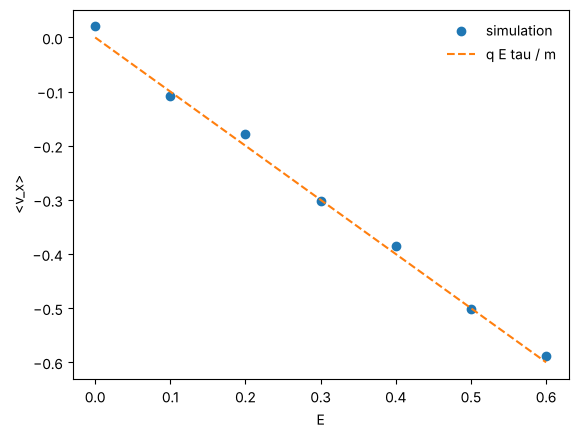

In [4]:
Es = np.linspace(0, 0.6, 7)
v_sim = [simulate((E, 0.0), 0.0, N=N // 2)[0] for E in Es]
plt.plot(Es, v_sim, 'o', label='simulation')
plt.plot(Es, charge * Es, '--', label='q E tau / m')
plt.xlabel('E'); plt.ylabel('<v_x>'); plt.legend(frameon=False); plt.show()

<div dir="rtl" style="text-align:right">

### 2. זווית הול
מפעילים שדה חשמלי בכיוון $x$ ושדה מגנטי $B$ (כאן $B=\omega_c\tau$, כי $m=q=\tau=1$). הזרם $\mathbf J=q n\langle\mathbf v\rangle$ אינו בהכרח בכיוון $\mathbf E$. מודדים את הזווית בין $\mathbf J$ ל-$\mathbf E$ ומשווים לתחזית של דרודה מהתרגול.

</div>

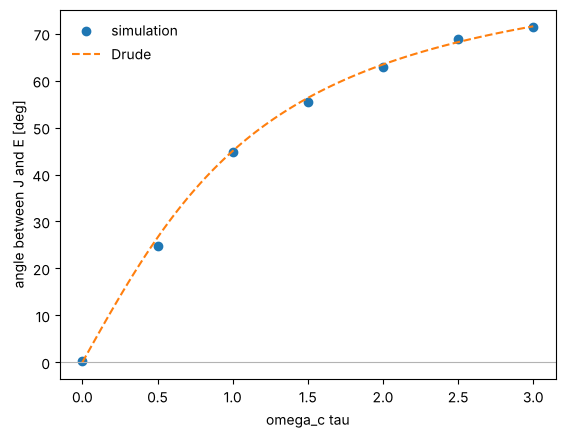

In [5]:
Bs = np.linspace(0, 3, 7)
angle = []
for B in Bs:
    v = simulate((E0, 0.0), B)
    J = charge * v                                     # current ~ q <v>
    angle.append(np.degrees(np.arctan2(J[1], J[0])))   # angle between J and E (E along x)
Bgrid = np.linspace(0, 3, 100)
plt.plot(Bs, angle, 'o', label='simulation')
plt.plot(Bgrid, np.degrees(-charge * np.arctan(Bgrid)), '--', label='Drude')
plt.xlabel('omega_c tau'); plt.ylabel('angle between J and E [deg]')
plt.axhline(0, color='0.7', lw=0.8); plt.legend(frameon=False); plt.show()

<div dir="rtl" style="text-align:right">

### 3. תגובה לשדה חשמלי תלוי בזמן
מפעילים שדה $E(t)=E_0\cos\omega t$ (ללא שדה מגנטי), ועוקבים אחרי המהירות הממוצעת $\langle v_x\rangle$ כפונקציה של הזמן, עבור שלושה תדרים. הקו המקווקו הוא הפרופיל של השדה עצמו (בקנה מידה). כשהתדר נמוך ($\omega\tau\ll1$) המהירות עוקבת אחרי השדה; מה קורה כשהוא עולה?

</div>

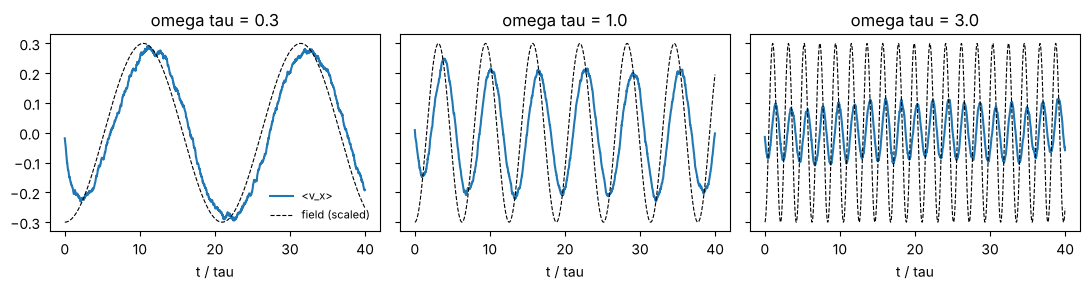

In [6]:
def ac_response(omega, T=40.0, dt=0.02, N=N):
    v = rng.normal(size=N)
    t = np.arange(int(T / dt)) * dt
    out = np.empty_like(t)
    for k, tk in enumerate(t):
        v = v + charge * E0 * np.cos(omega * tk) * dt
        hit = rng.random(N) < dt
        v[hit] = rng.normal(size=hit.sum())
        out[k] = v.mean()
    return t, out

fig, axs = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, omega in zip(axs, [0.3, 1.0, 3.0]):
    t, vx = ac_response(omega)
    ax.plot(t, vx, label='<v_x>')
    ax.plot(t, charge * E0 * np.cos(omega * t), 'k--', lw=0.8, label='field (scaled)')
    ax.set_title(f'omega tau = {omega}'); ax.set_xlabel('t / tau')
axs[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right">

### שאלות לדיון
1. מה קובע את שיפוע הגרף בחלק 1? מה היה משתנה אילו הזמן $\tau$ בין פיזורים היה ארוך יותר?
2. בחלק 2: מה קורה לזווית כש-$\omega_c\tau$ גדל, ולמה היא לא עוברת $90^\circ$?
3. בחלק 3: מה קורה לגודל התגובה ולמופע שלה ביחס לשדה כשהתדר עולה? מדוע (חשבו על $\tau$ כזמן שלוקח לנושא המטען "להגיב")? קשרו לביטוי $\sigma(\omega)=\sigma_D/(1-i\omega\tau)$ מהתרגול.

</div>